# 02 — RAR Baseline (SPARC only)

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

**Phase 2.** This notebook builds the acceleration data set for the eligible SPARC sample, implements the generalised RAR from proposal Section 4.1, and compares the data with the RAR evaluated at **published reference parameters**. Nothing is fitted.

**Not done here (later phases):** Bayesian inference, Gaussian-process (correlated-error) modelling, population comparisons, injection–recovery. The cross-survey feasibility gate did not pass in Phase 1, so this notebook uses **SPARC only** and does not use or approximate any THINGS, LITTLE THINGS or WALLABY baryonic data.

### How results are labelled

| Label | Meaning |
|---|---|
| **DATA** | Values copied unchanged from the SPARC files. |
| **DERIVED** | Computed from DATA with documented SPARC conventions (e.g. accelerations). |
| **REFERENCE** | Uses published reference parameters (a₀ = 1.20×10⁻¹⁰ m s⁻², β = 0.5, Υ★ = 0.5/0.7). These reproduce the literature relation; they are **not fitted results**. |
| **NEW DIAGNOSTIC** | New descriptive statistics of this data set relative to the reference curve (e.g. residual scatter). Descriptive only; not estimates of RAR parameters or intrinsic scatter. |

## 1. Environment Setup and Configuration

All paths and settings are defined in the configuration cell. The expected sample size (153 galaxies, 3,168 points) comes from the completed Phase 1 audit and is checked, not assumed.

In [1]:
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
REQUIRED_PACKAGES = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import os, re, json, hashlib, logging, platform, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
print(f"Run started (UTC): {RUN_TIMESTAMP} | Colab: {IN_COLAB}")
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")

Run started (UTC): 2026-10-22T08:50:33Z | Colab: True
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0


In [2]:
# =====================================================================
# CONFIGURATION — single place for paths and settings
# =====================================================================
DRIVE_MOUNT_POINT = Path("/content/drive")
DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))

# Original data (read-only)
DATASETS_DIR = PROJECT_ROOT / "01_Datasets"
SPARC_MRT    = DATASETS_DIR / "SPARC" / "SPARC_Lelli2016c.mrt"
ROTMOD_DIR   = DATASETS_DIR / "SPARC" / "Rotmod_LTG"
UNIFIED_CSV  = DATASETS_DIR / "UNIFIED_HI" / "rotation_curve_corpus_v7.1_flat.csv"   # used only to cross-check SPARC D and i

# Existing output folders created in Phase 1
PROCESSED_DIR      = PROJECT_ROOT / "03_Processed_Data"
RESULTS_TABLES_DIR = PROJECT_ROOT / "05_Results" / "Tables"
FIGURES_DIR        = PROJECT_ROOT / "05_Results" / "Figures"
LOG_DIR            = PROCESSED_DIR / "logs"

# Phase 1 outputs used here
P1 = {
    "galaxy_audit":   PROCESSED_DIR / "sparc_galaxy_audit.csv",
    "points_audit":   PROCESSED_DIR / "sparc_rotation_points_audit.csv",
    "cut_summary":    PROCESSED_DIR / "sparc_quality_cut_summary.csv",
    "integrity":      PROCESSED_DIR / "integrity_checks.csv",
    "manifest":       PROCESSED_DIR / "input_file_manifest.csv",
    "report":         RESULTS_TABLES_DIR / "Dataset_Feasibility_Report.md",
}

# Phase 2 outputs
OUT_POINTS   = PROCESSED_DIR / "sparc_rar_points_baseline.csv"
OUT_GALAXIES = PROCESSED_DIR / "sparc_rar_galaxies_baseline.csv"
OUT_BINNED   = PROCESSED_DIR / "rar_reference_residuals_binned.csv"
OUT_REFPARS  = PROCESSED_DIR / "rar_reference_parameters.csv"
OUT_EXCL     = PROCESSED_DIR / "sparc_rar_point_exclusions.csv"
OUT_WARN     = PROCESSED_DIR / "phase1_warning_assessment.csv"
OUT_CHECKS   = PROCESSED_DIR / "02_integrity_checks.csv"
OUT_DICT     = PROCESSED_DIR / "02_data_dictionary.csv"
OUT_NPZ      = PROCESSED_DIR / "sparc_rar_model_inputs.npz"
OUT_NPZ_META = PROCESSED_DIR / "sparc_rar_model_inputs_metadata.json"
OUT_MANIFEST = PROCESSED_DIR / "02_output_manifest.csv"
REPORT_PATH  = RESULTS_TABLES_DIR / "RAR_Baseline_Report.md"
LOG_PATH     = LOG_DIR / "02_rar_baseline.log"

# Sample expected from the completed Phase 1 audit (override only for local testing)
EXPECTED_N_GALAXIES = int(os.environ.get("RAR_EXPECTED_N_GALAXIES", 153))
EXPECTED_N_POINTS   = int(os.environ.get("RAR_EXPECTED_N_POINTS", 3168))
Q_MAX, INC_MIN_DEG  = 2, 30.0           # proposal Section 3 (re-verified, not re-chosen)

# Physical constants and unit conversions
KPC_IN_M  = 3.0856775814913673e19     # 1 kpc in m (IAU 2012 au / parsec definition)
KMS_IN_MS = 1.0e3                     # 1 km/s in m/s
LN10      = np.log(10.0)

# REFERENCE parameters (published values; NOT fitted here)
REF = {
    "a0_ms2":        1.20e-10,  # McGaugh, Lelli & Schombert 2016, PRL 117, 201101: g† = 1.20 ± 0.02 (rand) ± 0.24 (syst) × 1e-10 m/s^2
    "beta":          0.5,       # proposal Section 4.1: beta = 0.5 recovers the standard form
    "upsilon_disk":  0.5,       # [3.6] stellar M/L for disks used by McGaugh et al. 2016 / Lelli et al. 2016
    "upsilon_bulge": 0.7,       # [3.6] stellar M/L for bulges used by McGaugh et al. 2016 / Lelli et al. 2016
}
# Literature context quoted for comparison only (from McGaugh et al. 2016; verify against the paper before citing)
LITERATURE_CONTEXT = {"n_points": 2693, "n_galaxies": 153, "observed_scatter_dex": 0.13}

N_BINS_LOG_GBAR = 20          # bins in log g_bar for binned residual statistics
MIN_POINTS_BIN  = 10          # bins with fewer points are reported but not plotted as statistics
MIN_POINTS_AUTOCORR = 5       # minimum points per galaxy for the lag-1 residual autocorrelation diagnostic
print("Project root:", PROJECT_ROOT)

Project root: /content/drive/MyDrive/RAR_Universality_Research


## 2. Google Drive Mounting

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
    if not DRIVE_ROOT.exists():
        raise FileNotFoundError(f"Drive mounted but {DRIVE_ROOT} not found; re-run and complete authorisation.")
else:
    print("Not in Colab: using PROJECT_ROOT =", PROJECT_ROOT)

Mounted at /content/drive


## 3. Verify Required Files and Data Integrity

Checks that the original SPARC files and all Phase 1 outputs exist, that the output folders from Phase 1 exist, and that the SPARC files are **byte-for-byte unchanged** since Phase 1 (SHA-256 compared with `input_file_manifest.csv`).

In [4]:
def _ls(p):
    return ", ".join(sorted(x.name for x in p.iterdir())[:30]) if p.is_dir() else "(missing)"

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}. Parent contains: {_ls(PROJECT_ROOT.parent)}")
problems = []
for label, path in {"SPARC MRT": SPARC_MRT, **{f"Phase 1 {k}": v for k, v in P1.items()}}.items():
    if not path.is_file():
        problems.append(f"- {label}: {path} (folder contains: {_ls(path.parent)})")
if not ROTMOD_DIR.is_dir():
    problems.append(f"- Rotmod_LTG folder: {ROTMOD_DIR}")
for d in (PROCESSED_DIR, RESULTS_TABLES_DIR, FIGURES_DIR):
    if not d.is_dir():
        problems.append(f"- output folder from Phase 1 missing: {d}")
if problems:
    raise FileNotFoundError("Missing required inputs. Run 01_Data_Audit.ipynb first, then check:\n" + "\n".join(problems))
LOG_DIR.mkdir(exist_ok=True)

logger = logging.getLogger("rar_phase2"); logger.setLevel(logging.INFO); logger.handlers.clear()
_fh = logging.FileHandler(LOG_PATH, mode="w", encoding="utf-8")
_fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status, "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(f"[{status}] {section} | {name} | {detail}")
    return bool(passed)

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

manifest = pd.read_csv(P1["manifest"])
sparc_manifest = manifest[manifest.relative_path.str.contains("01_Datasets/SPARC/", regex=False)]
if sparc_manifest.empty:
    raise ValueError("Phase 1 manifest has no SPARC entries; cannot verify the original files.")
changed, missing_now = [], []
for r in sparc_manifest.itertuples():
    f = PROJECT_ROOT / r.relative_path
    if not f.is_file():
        missing_now.append(r.relative_path)
    elif sha256_of(f) != r.sha256:
        changed.append(r.relative_path)
current_rotmod = sorted(p.name for p in ROTMOD_DIR.glob("*_rotmod.dat"))
extra_now = sorted(set(current_rotmod) - set(sparc_manifest.file))
record_check("Inputs", "SPARC files unchanged since Phase 1 (SHA-256)", not changed and not missing_now,
             f"changed: {changed[:5]}; missing: {missing_now[:5]}" if (changed or missing_now) else f"{len(sparc_manifest)} files verified")
record_check("Inputs", "no new rotmod files since Phase 1", not extra_now, extra_now[:5] or "none", severity="warning")
if changed or missing_now:
    raise RuntimeError("Original SPARC files differ from the Phase 1 audit. Re-run Phase 1 before continuing.")
print(f"Verified {len(sparc_manifest)} original SPARC files against the Phase 1 checksums.")

INFO: [PASS] Inputs | SPARC files unchanged since Phase 1 (SHA-256) | 176 files verified


INFO:rar_phase2:[PASS] Inputs | SPARC files unchanged since Phase 1 (SHA-256) | 176 files verified


INFO: [PASS] Inputs | no new rotmod files since Phase 1 | none


INFO:rar_phase2:[PASS] Inputs | no new rotmod files since Phase 1 | none


Verified 176 original SPARC files against the Phase 1 checksums.


## 4. Inspect the Phase 1 Warnings

Each Phase 1 warning is listed with its relevance to a SPARC-only baseline. The one warning that touches SPARC (the MRT row layout) is **re-tested independently**: distances, inclinations and their errors parsed in Phase 1 are compared with the same quantities in the unified corpus CSV, which was built from the SPARC table by a different pipeline.

In [5]:
p1_checks = pd.read_csv(P1["integrity"])
p1_warn = p1_checks[p1_checks.status == "WARN"].reset_index(drop=True)
p1_fail = p1_checks[p1_checks.status == "FAIL"]
record_check("Phase 1", "Phase 1 has no critical failures", p1_fail.empty, f"{len(p1_fail)} FAIL rows")
print(f"Phase 1 checks: {len(p1_checks)} total, {len(p1_warn)} warnings, {len(p1_fail)} failures")
display(p1_warn[["section", "check", "detail"]])

INFO: [PASS] Phase 1 | Phase 1 has no critical failures | 0 FAIL rows


INFO:rar_phase2:[PASS] Phase 1 | Phase 1 has no critical failures | 0 FAIL rows


Phase 1 checks: 62 total, 4 warnings, 0 failures


,section,check,detail
0,SPARC MRT,data rows follow the declared byte positions,whitespace_tokens (declared byte positions did...
1,Unified JSON,LITTLE_THINGS: observed per-ring columns match...,"documented ['Rad', 'Vrot', 'errV']; observed [..."
2,Unified CSV,n_points agrees with JSON data arrays,"[['NGC628', 'THINGS', nan, 0], ['NGC1569', 'TH..."
3,Unified CSV,column count matches README description,"README says 38, file has 31 (v7.1 CSV vs v7.0 ..."


In [6]:
# Independent re-test of the MRT parse (Phase 1 warning on row layout)
gal_p1 = pd.read_csv(P1["galaxy_audit"])
mrt_crosscheck = {"status": "not run", "n_compared": 0, "max_abs_diff": {}}
if UNIFIED_CSV.is_file():
    flat = pd.read_csv(UNIFIED_CSV)
    flat_sp = flat[flat["survey"].astype(str).str.upper() == "SPARC"]
    pairs = [("distance_mpc", "distance_mpc"), ("e_distance_mpc", "e_distance_mpc"),
             ("inc_deg", "inc_deg"), ("e_inc_deg", "e_inc_deg")]
    pairs = [(a, b) for a, b in pairs if a in gal_p1.columns and b in flat_sp.columns]
    m = gal_p1.merge(flat_sp[["galaxy"] + [b for _, b in pairs]], on="galaxy", suffixes=("_p1", "_corpus"))
    diffs = {}
    for a, b in pairs:
        both = m[[f"{a}_p1", f"{b}_corpus"]].apply(pd.to_numeric, errors="coerce").dropna()
        if len(both):                       # compare only where the corpus actually has the value
            diffs[a] = float(np.max(np.abs(both.iloc[:, 0] - both.iloc[:, 1])))
    ok = len(m) > 0 and len(diffs) > 0 and all(d <= 1e-6 for d in diffs.values())
    mrt_crosscheck = {"status": "match" if ok else "MISMATCH", "n_compared": len(m), "max_abs_diff": diffs}
    record_check("Phase 1 warning", "MRT parse agrees with independent corpus values (D, e_D, i, e_i)", ok,
                 f"{len(m)} galaxies compared; max |diff| {diffs}")
else:
    record_check("Phase 1 warning", "MRT parse cross-check possible", False, "unified CSV not found", severity="warning")
# Internal plausibility of the parsed quality flags and inclinations
in_mrt = gal_p1[gal_p1["in_mrt"].astype(bool)] if "in_mrt" in gal_p1 else gal_p1
q_ok = in_mrt["quality_flag_Q"].isin([1, 2, 3]).all()
i_ok = in_mrt["inc_deg"].between(0, 90).all()
record_check("Phase 1 warning", "parsed Q in {1,2,3} and inclinations in [0, 90] deg", bool(q_ok and i_ok),
             f"Q values {sorted(gal_p1.quality_flag_Q.dropna().unique().tolist())}")
print("Cross-check result:", mrt_crosscheck)

def assess(row):
    sec, chk = str(row.section), str(row.check)
    if sec.startswith("SPARC MRT") and "byte positions" in chk:
        return ("yes - Q and inclination drive the sample cuts",
                f"Re-tested: Phase 1 values {'agree' if mrt_crosscheck['status']=='match' else 'DO NOT agree'} with the "
                f"corpus for {mrt_crosscheck['n_compared']} galaxies; Q and i ranges valid. No action needed if 'agree'.")
    if sec.startswith("SPARC"):
        return ("possibly - SPARC input", "Review the detail; this notebook re-reads the raw rotmod files and re-checks them.")
    if sec.startswith("Unified") or sec.startswith("Corpus"):
        return ("no - unified-corpus field not used in a SPARC-only baseline",
                "Record for later; relevant only if the cross-survey extension is revisited.")
    return ("unclear", "Review manually.")

warn_assessment = p1_warn.copy()
warn_assessment[["affects_notebook_02", "assessment"]] = warn_assessment.apply(lambda r: pd.Series(assess(r)), axis=1)
display(warn_assessment[["section", "check", "affects_notebook_02", "assessment"]])

INFO: [PASS] Phase 1 warning | MRT parse agrees with independent corpus values (D, e_D, i, e_i) | 175 galaxies compared; max |diff| {'distance_mpc': 0.0, 'e_distance_mpc': 0.0, 'inc_deg': 0.0, 'e_inc_deg': 0.0}


INFO:rar_phase2:[PASS] Phase 1 warning | MRT parse agrees with independent corpus values (D, e_D, i, e_i) | 175 galaxies compared; max |diff| {'distance_mpc': 0.0, 'e_distance_mpc': 0.0, 'inc_deg': 0.0, 'e_inc_deg': 0.0}


INFO: [PASS] Phase 1 warning | parsed Q in {1,2,3} and inclinations in [0, 90] deg | Q values [1, 2, 3]


INFO:rar_phase2:[PASS] Phase 1 warning | parsed Q in {1,2,3} and inclinations in [0, 90] deg | Q values [1, 2, 3]


Cross-check result: {'status': 'match', 'n_compared': 175, 'max_abs_diff': {'distance_mpc': 0.0, 'e_distance_mpc': 0.0, 'inc_deg': 0.0, 'e_inc_deg': 0.0}}


,section,check,affects_notebook_02,assessment
0,SPARC MRT,data rows follow the declared byte positions,yes - Q and inclination drive the sample cuts,Re-tested: Phase 1 values agree with the corpu...
1,Unified JSON,LITTLE_THINGS: observed per-ring columns match...,no - unified-corpus field not used in a SPARC-...,Record for later; relevant only if the cross-s...
2,Unified CSV,n_points agrees with JSON data arrays,no - unified-corpus field not used in a SPARC-...,Record for later; relevant only if the cross-s...
3,Unified CSV,column count matches README description,no - unified-corpus field not used in a SPARC-...,Record for later; relevant only if the cross-s...


## 5. Load the Eligible SPARC Sample

The eligible galaxies are those marked `passes_quality_cuts` in Phase 1 (Q ≤ 2, i ≥ 30°). The cut is **re-applied here from the parsed Q and inclination** to confirm it, and the counts must equal 153 galaxies and 3,168 points.

The rotation-curve values are then **re-read from the original rotmod files** and compared with the Phase 1 point table, so this notebook does not depend on any intermediate copy of the data.

In [7]:
eligible_p1 = set(gal_p1.loc[gal_p1["passes_quality_cuts"].astype(bool), "galaxy"])
recomputed = set(gal_p1.loc[(gal_p1.quality_flag_Q <= Q_MAX) & (gal_p1.inc_deg >= INC_MIN_DEG)
                            & gal_p1.rotmod_parse_ok.astype(bool), "galaxy"])
record_check("Sample", "re-applied cuts reproduce the Phase 1 eligible set", eligible_p1 == recomputed,
             f"only Phase 1: {sorted(eligible_p1 - recomputed)}; only recomputed: {sorted(recomputed - eligible_p1)}")
record_check("Sample", f"eligible galaxies = {EXPECTED_N_GALAXIES}", len(eligible_p1) == EXPECTED_N_GALAXIES,
             f"{len(eligible_p1)} galaxies")

def read_rotmod(path):
    lines = path.read_text(encoding="ascii", errors="replace").splitlines()
    hdr = [l.lstrip()[1:].strip() for l in lines if l.lstrip().startswith("#")]
    names = next(h.split() for h in hdr if h.startswith("Rad"))
    rows = [l.split() for l in lines if l.strip() and not l.lstrip().startswith("#")]
    if {len(r) for r in rows} != {len(names)}:
        raise ValueError(f"{path.name}: column count mismatch")
    t = pd.DataFrame(rows, columns=names).apply(pd.to_numeric, errors="raise")
    m = re.search(r"Distance\s*=\s*([0-9.]+)\s*Mpc", " ".join(hdr))
    return t, (float(m.group(1)) if m else np.nan)

frames, hdr_dist = [], {}
for g in sorted(eligible_p1):
    f = ROTMOD_DIR / f"{g}_rotmod.dat"
    if not f.is_file():
        raise FileNotFoundError(f"Eligible galaxy {g} has no rotmod file at {f}")
    t, d = read_rotmod(f)
    t.insert(0, "galaxy", g); t.insert(1, "point_index", np.arange(len(t)))
    frames.append(t); hdr_dist[g] = d
raw = pd.concat(frames, ignore_index=True)
DATA_COLS = ["Rad", "Vobs", "errV", "Vgas", "Vdisk", "Vbul", "SBdisk", "SBbul"]
missing_cols = [c for c in DATA_COLS if c not in raw.columns]
if missing_cols:
    raise KeyError(f"rotmod files lack required columns {missing_cols}")
record_check("Sample", f"eligible radial points = {EXPECTED_N_POINTS}", len(raw) == EXPECTED_N_POINTS, f"{len(raw)} points")

# Compare with the Phase 1 point table (values must be identical)
pts_p1 = pd.read_csv(P1["points_audit"])
pts_p1 = pts_p1[pts_p1.galaxy.isin(eligible_p1)]
cmp = raw.merge(pts_p1[["galaxy", "point_index"] + DATA_COLS], on=["galaxy", "point_index"],
                suffixes=("", "_p1"), how="outer", indicator=True)
unmatched = int((cmp._merge != "both").sum())
maxdiff = max(float(np.nanmax(np.abs(cmp[c] - cmp[f"{c}_p1"]))) for c in DATA_COLS) if unmatched == 0 else np.nan
record_check("Sample", "raw rotmod values identical to the Phase 1 point table", unmatched == 0 and maxdiff == 0.0,
             f"unmatched rows {unmatched}; max |diff| {maxdiff}")
RAW_CHECKSUM = hashlib.sha256(pd.util.hash_pandas_object(raw[["galaxy"] + DATA_COLS], index=False).values.tobytes()).hexdigest()
print(f"Loaded {raw.galaxy.nunique()} galaxies and {len(raw)} radial points from the original rotmod files.")
display(raw.head())

INFO: [PASS] Sample | re-applied cuts reproduce the Phase 1 eligible set | only Phase 1: []; only recomputed: []


INFO:rar_phase2:[PASS] Sample | re-applied cuts reproduce the Phase 1 eligible set | only Phase 1: []; only recomputed: []


INFO: [PASS] Sample | eligible galaxies = 153 | 153 galaxies


INFO:rar_phase2:[PASS] Sample | eligible galaxies = 153 | 153 galaxies


INFO: [PASS] Sample | eligible radial points = 3168 | 3168 points


INFO:rar_phase2:[PASS] Sample | eligible radial points = 3168 | 3168 points


INFO: [PASS] Sample | raw rotmod values identical to the Phase 1 point table | unmatched rows 0; max |diff| 0.0


INFO:rar_phase2:[PASS] Sample | raw rotmod values identical to the Phase 1 point table | unmatched rows 0; max |diff| 0.0


Loaded 153 galaxies and 3168 radial points from the original rotmod files.


,galaxy,point_index,Rad,Vobs,errV,Vgas,Vdisk,Vbul,SBdisk,SBbul
0,CamB,0,0.16,1.99,1.5,1.86,3.75,0.0,30.32,0.0
1,CamB,1,0.41,4.84,1.5,4.24,9.47,0.0,23.77,0.0
2,CamB,2,0.57,6.79,1.5,5.61,11.76,0.0,15.87,0.0
3,CamB,3,0.73,8.87,1.5,6.77,13.72,0.0,12.40,0.0
4,CamB,4,0.90,10.90,1.5,7.77,14.80,0.0,9.63,0.0


## 6. Observed and Baryonic Accelerations (SPARC conventions)

**DERIVED quantities, SI units (m s⁻²).** With R in kpc and velocities in km s⁻¹:

* Observed: g_obs = V_obs² / R.
* Baryonic: g_bar = V_bar² / R, with V_bar² = V_gas·|V_gas| + Υ_disk·V_disk² + Υ_bulge·V_bul².

SPARC conventions (Lelli et al. 2016; corpus README Section 7.2): disk and bulge contributions are tabulated for Υ★ = 1, so they scale with Υ★ inside the square; V_gas is used exactly as provided and can be negative at small radii, which is why it enters as V_gas·|V_gas|. The REFERENCE M/L values are Υ_disk = 0.5 and Υ_bulge = 0.7.

To keep everything later phases need, each point also stores the **separate** gas, disk (Υ=1) and bulge (Υ=1) accelerations. g_bar can then be recomputed for any Υ★ without re-reading the files.

**Uncertainties stored for later modelling** (base-10 log space):

* σ_V = 2·errV / (V_obs·ln10): independent per point (Σ_V in proposal Section 4.2).
* σ_D = e_D / (D·ln10) and σ_i = 2·e_i / (tan i·ln10) (e_i in radians): these come from galaxy-level distance and inclination errors and are **fully correlated within a galaxy**. They are stored separately and are **not** to be added in quadrature to σ_V in later fits; the proposal samples D and i explicitly.

In [8]:
gal_cols = ["galaxy", "distance_mpc", "e_distance_mpc", "inc_deg", "e_inc_deg", "quality_flag_Q", "hubble_type_T",
            "L36_1e9Lsun", "MHI_1e9Msun", "SBdisk0_Lsun_pc2", "SBeff_Lsun_pc2", "Rdisk_kpc", "Reff_kpc",
            "Vflat_kms", "e_Vflat_kms", "distance_method_code"]
gal_cols = [c for c in gal_cols if c in gal_p1.columns]
df = raw.merge(gal_p1[gal_cols], on="galaxy", how="left", validate="many_to_one")
if df["distance_mpc"].isna().any() or df["inc_deg"].isna().any():
    raise ValueError("Some eligible points lack galaxy distance or inclination after the merge.")

R_m = df["Rad"] * KPC_IN_M
to_si = KMS_IN_MS ** 2 / R_m                                   # converts (km/s)^2 / kpc -> m/s^2
df["g_obs"]          = df["Vobs"] ** 2 * to_si                 # DERIVED
df["g_gas"]          = df["Vgas"] * df["Vgas"].abs() * to_si   # DERIVED (signed, SPARC convention)
df["g_disk_ups1"]    = df["Vdisk"] ** 2 * to_si                # DERIVED, Upsilon_disk = 1
df["g_bul_ups1"]     = df["Vbul"] ** 2 * to_si                 # DERIVED, Upsilon_bulge = 1
df["g_bar_ref"]      = df["g_gas"] + REF["upsilon_disk"] * df["g_disk_ups1"] + REF["upsilon_bulge"] * df["g_bul_ups1"]  # REFERENCE M/L
df["Vbar_ref_kms"]   = np.sign(df["g_bar_ref"]) * np.sqrt(np.abs(df["g_bar_ref"]) / to_si)

with np.errstate(divide="ignore", invalid="ignore"):
    df["log_g_obs"]      = np.where(df["g_obs"] > 0, np.log10(df["g_obs"]), np.nan)
    df["log_g_bar_ref"]  = np.where(df["g_bar_ref"] > 0, np.log10(df["g_bar_ref"]), np.nan)
    df["sigma_log_gobs_V"] = 2.0 * df["errV"] / (df["Vobs"] * LN10)
    df["sigma_log_gobs_D_galaxy"] = df["e_distance_mpc"] / (df["distance_mpc"] * LN10)
    df["sigma_log_gobs_inc_galaxy"] = 2.0 * np.radians(df["e_inc_deg"]) / (np.tan(np.radians(df["inc_deg"])) * LN10)
df["galaxy_index"] = df["galaxy"].map({g: i for i, g in enumerate(sorted(df.galaxy.unique()))}).astype(int)
df["R_over_Rmax"] = df["Rad"] / df.groupby("galaxy")["Rad"].transform("max")
display(df[["galaxy", "Rad", "Vobs", "g_obs", "g_bar_ref", "log_g_obs", "log_g_bar_ref", "sigma_log_gobs_V"]].head())

,galaxy,Rad,Vobs,g_obs,g_bar_ref,log_g_obs,log_g_bar_ref,sigma_log_gobs_V
0,CamB,0.16,1.99,8.021131e-13,2.124908e-12,-12.095764,-11.672660,0.654715
1,CamB,0.41,4.84,1.851639e-12,4.965352e-12,-11.732444,-11.304050,0.269191
2,CamB,0.57,6.79,2.621284e-12,5.720879e-12,-11.581486,-11.242537,0.191883
3,CamB,0.73,8.87,3.492801e-12,6.213067e-12,-11.456826,-11.206694,0.146887
4,CamB,0.90,10.90,4.278189e-12,6.117615e-12,-11.368740,-11.213418,0.119531


## 7. Point-Level Numerical Exclusions (transparent)

No observational value is changed or deleted. A point is only **excluded from log-space analysis** if a logarithm or uncertainty cannot be computed: R ≤ 0, V_obs ≤ 0, errV ≤ 0, non-finite values, or g_bar ≤ 0 at the reference Υ★.

g_bar ≤ 0 happens where a negative gas term outweighs the stellar terms. It **depends on Υ★**, so such points are kept in every table with a flag. Later phases that sample Υ★ can include them again.

In [9]:
excl = pd.DataFrame(index=df.index)
excl["R_nonpositive"]        = df["Rad"] <= 0
excl["Vobs_nonpositive"]     = df["Vobs"] <= 0
excl["errV_nonpositive"]     = df["errV"] <= 0
excl["nonfinite_input"]      = ~np.isfinite(df[DATA_COLS]).all(axis=1)
excl["g_bar_ref_nonpositive_(depends_on_Upsilon)"] = df["g_bar_ref"] <= 0
df["exclusion_reason"] = excl.apply(lambda r: "; ".join(c for c in excl.columns if r[c]), axis=1)
df["included_in_log_analysis"] = df["exclusion_reason"] == ""

excl_summary = pd.DataFrame({"n_points": excl.sum().astype(int),
                             "n_galaxies": [int(df.loc[excl[c], "galaxy"].nunique()) for c in excl.columns]})
display(excl_summary)
use = df[df.included_in_log_analysis].copy()
N_USE, G_USE = len(use), use.galaxy.nunique()
print(f"Points used in log-space analysis: {N_USE} of {len(df)} ({len(df) - N_USE} excluded) in {G_USE} galaxies.")
lost = sorted(set(df.galaxy) - set(use.galaxy))
record_check("Exclusions", "no galaxy loses all its points", not lost, lost or "none", severity="warning")
record_check("Exclusions", "excluded points are a small fraction (< 5%)", (len(df) - N_USE) / len(df) < 0.05,
             f"{len(df) - N_USE} points", severity="warning")
exclusions_table = df.loc[~df.included_in_log_analysis, ["galaxy", "point_index", "Rad", "Vobs", "errV", "Vgas",
                                                          "Vdisk", "Vbul", "g_bar_ref", "exclusion_reason"]]
for r in exclusions_table.itertuples():
    logger.info(f"EXCLUDED POINT {r.galaxy}[{r.point_index}] R={r.Rad}: {r.exclusion_reason}")

,n_points,n_galaxies
R_nonpositive,0,0
Vobs_nonpositive,0,0
errV_nonpositive,0,0
nonfinite_input,0,0
g_bar_ref_nonpositive_(depends_on_Upsilon),2,1


Points used in log-space analysis: 3166 of 3168 (2 excluded) in 153 galaxies.
INFO: [PASS] Exclusions | no galaxy loses all its points | none


INFO:rar_phase2:[PASS] Exclusions | no galaxy loses all its points | none


INFO: [PASS] Exclusions | excluded points are a small fraction (< 5%) | 2 points


INFO:rar_phase2:[PASS] Exclusions | excluded points are a small fraction (< 5%) | 2 points


INFO: EXCLUDED POINT UGC01281[0] R=0.08: g_bar_ref_nonpositive_(depends_on_Upsilon)


INFO:rar_phase2:EXCLUDED POINT UGC01281[0] R=0.08: g_bar_ref_nonpositive_(depends_on_Upsilon)


INFO: EXCLUDED POINT UGC01281[1] R=0.23: g_bar_ref_nonpositive_(depends_on_Upsilon)


INFO:rar_phase2:EXCLUDED POINT UGC01281[1] R=0.23: g_bar_ref_nonpositive_(depends_on_Upsilon)


## 8. Generalised RAR (proposal Section 4.1)

$$ g_\mathrm{obs} = \frac{g_\mathrm{bar}}{1 - \exp\!\left[-\left(g_\mathrm{bar}/a_0\right)^{\beta}\right]} $$

Limits: g_obs → g_bar when g_bar ≫ a₀; g_obs → g_bar^(1−β) a₀^β when g_bar ≪ a₀ (log-log slope 1 − β). β = 0.5 gives the standard form. The implementation uses `expm1` for numerical stability at small x, and the unit tests below check both limits, the β = 0.5 special case, monotonicity and the asymptotic slope.

In [10]:
def rar_generalized(g_bar, a0, beta):
    # Generalised RAR (proposal Sec. 4.1). g_bar and a0 in m/s^2; returns g_obs in m/s^2. Requires g_bar > 0.
    g_bar = np.asarray(g_bar, dtype=float)
    if np.any(g_bar <= 0):
        raise ValueError("rar_generalized requires g_bar > 0")
    if a0 <= 0 or beta <= 0:
        raise ValueError("a0 and beta must be positive")
    x = (g_bar / a0) ** beta
    return g_bar / (-np.expm1(-x))          # 1 - exp(-x) computed stably

def log_rar_generalized(log_g_bar, log_a0, beta):
    # f(x; a0, beta) in proposal notation: log10 of the RAR prediction given log10 g_bar.
    return np.log10(rar_generalized(10.0 ** np.asarray(log_g_bar, float), 10.0 ** log_a0, beta))

# --- unit tests ---
a0, b = REF["a0_ms2"], REF["beta"]
g_hi, g_lo = np.array([1e-7]), np.array([1e-15])
tests = {
    "high-g limit: g_obs/g_bar -> 1 (g_bar = 1e3 a0)": abs(rar_generalized(g_hi, a0, b)[0] / g_hi[0] - 1) < 1e-6,
    "low-g limit: g_obs -> sqrt(g_bar a0) for beta=0.5": abs(rar_generalized(g_lo, a0, b)[0] / np.sqrt(g_lo[0] * a0) - 1) < 1e-2,
    "low-g limit general beta=0.3: g_bar^(0.7) a0^0.3 (g_bar = 1e-22)":
        abs(rar_generalized(np.array([1e-22]), a0, 0.3)[0] / (1e-22 ** 0.7 * a0 ** 0.3) - 1) < 1e-2,
    "beta=0.5 equals McGaugh+2016 form": np.allclose(rar_generalized(np.logspace(-13, -8, 50), a0, 0.5),
        np.logspace(-13, -8, 50) / (1 - np.exp(-np.sqrt(np.logspace(-13, -8, 50) / a0))), rtol=1e-12),
    "value at g_bar = a0 equals a0/(1-1/e)": np.isclose(rar_generalized(np.array([a0]), a0, b)[0], a0 / (1 - np.exp(-1))),
    "monotonically increasing": bool(np.all(np.diff(rar_generalized(np.logspace(-14, -7, 400), a0, b)) > 0)),
    "g_obs >= g_bar everywhere": bool(np.all(rar_generalized(np.logspace(-14, -7, 400), a0, b) >= np.logspace(-14, -7, 400))),
    "asymptotic log-log slope = 1 - beta": abs(np.diff(log_rar_generalized(np.array([-17.0, -16.0]), np.log10(a0), b))[0] - (1 - b)) < 1e-2,
    "log wrapper consistent": np.isclose(log_rar_generalized(np.array([-10.5]), np.log10(a0), b)[0],
                                         np.log10(rar_generalized(np.array([10 ** -10.5]), a0, b)[0])),
}
for name, ok in tests.items():
    record_check("RAR function", name, bool(ok))
display(pd.DataFrame({"test": list(tests), "passed": [bool(v) for v in tests.values()]}))

INFO: [PASS] RAR function | high-g limit: g_obs/g_bar -> 1 (g_bar = 1e3 a0) | 


INFO:rar_phase2:[PASS] RAR function | high-g limit: g_obs/g_bar -> 1 (g_bar = 1e3 a0) | 


INFO: [PASS] RAR function | low-g limit: g_obs -> sqrt(g_bar a0) for beta=0.5 | 


INFO:rar_phase2:[PASS] RAR function | low-g limit: g_obs -> sqrt(g_bar a0) for beta=0.5 | 


INFO: [PASS] RAR function | low-g limit general beta=0.3: g_bar^(0.7) a0^0.3 (g_bar = 1e-22) | 


...

INFO: [PASS] RAR function | asymptotic log-log slope = 1 - beta | 


INFO:rar_phase2:[PASS] RAR function | asymptotic log-log slope = 1 - beta | 


INFO: [PASS] RAR function | log wrapper consistent | 


INFO:rar_phase2:[PASS] RAR function | log wrapper consistent | 


,test,passed
0,high-g limit: g_obs/g_bar -> 1 (g_bar = 1e3 a0),True
1,low-g limit: g_obs -> sqrt(g_bar a0) for beta=0.5,True
2,low-g limit general beta=0.3: g_bar^(0.7) a0^0...,True
3,beta=0.5 equals McGaugh+2016 form,True
4,value at g_bar = a0 equals a0/(1-1/e),True
5,monotonically increasing,True
6,g_obs >= g_bar everywhere,True
7,asymptotic log-log slope = 1 - beta,True
8,log wrapper consistent,True


## 9. Reference RAR Reproduction

**REFERENCE:** the curve below is the generalised RAR evaluated at a₀ = 1.20×10⁻¹⁰ m s⁻², β = 0.5, with g_bar computed at Υ_disk = 0.5 and Υ_bulge = 0.7. These are published values used as a fixed baseline. **They are not fitted to these data, and nothing in this section estimates a₀, β or the intrinsic scatter.**

**NEW DIAGNOSTIC:** residuals Δ = log g_obs − f(log g_bar; a₀,ref, β_ref) describe how this data set sits relative to the reference curve.

In [11]:
ref_pars = pd.DataFrame([
    {"parameter": "a0", "value": REF["a0_ms2"], "unit": "m s^-2", "role": "REFERENCE (not fitted)",
     "source": "McGaugh, Lelli & Schombert 2016, PRL 117, 201101 (g-dagger = 1.20 +/- 0.02 rand +/- 0.24 syst x 1e-10)"},
    {"parameter": "beta", "value": REF["beta"], "unit": "-", "role": "REFERENCE (not fitted)",
     "source": "Proposal Sec. 4.1: beta = 0.5 recovers the standard RAR form"},
    {"parameter": "Upsilon_disk_3.6um", "value": REF["upsilon_disk"], "unit": "Msun/Lsun", "role": "REFERENCE (not fitted)",
     "source": "McGaugh et al. 2016; Lelli et al. 2016 (SPARC)"},
    {"parameter": "Upsilon_bulge_3.6um", "value": REF["upsilon_bulge"], "unit": "Msun/Lsun", "role": "REFERENCE (not fitted)",
     "source": "McGaugh et al. 2016; Lelli et al. 2016 (SPARC)"},
    {"parameter": "literature_n_points", "value": LITERATURE_CONTEXT["n_points"], "unit": "-", "role": "LITERATURE CONTEXT",
     "source": "McGaugh et al. 2016 sample after additional point-level cuts (not applied in this project)"},
    {"parameter": "literature_n_galaxies", "value": LITERATURE_CONTEXT["n_galaxies"], "unit": "-", "role": "LITERATURE CONTEXT",
     "source": "McGaugh et al. 2016"},
    {"parameter": "literature_observed_scatter", "value": LITERATURE_CONTEXT["observed_scatter_dex"], "unit": "dex", "role": "LITERATURE CONTEXT",
     "source": "McGaugh et al. 2016 (observed scatter about the relation)"},
])
display(ref_pars)

use["log_g_rar_ref"] = log_rar_generalized(use["log_g_bar_ref"], np.log10(REF["a0_ms2"]), REF["beta"])
use["resid_ref_dex"] = use["log_g_obs"] - use["log_g_rar_ref"]
use["resid_ref_over_sigmaV"] = use["resid_ref_dex"] / use["sigma_log_gobs_V"]
df = df.merge(use[["galaxy", "point_index", "log_g_rar_ref", "resid_ref_dex", "resid_ref_over_sigmaV"]],
              on=["galaxy", "point_index"], how="left")

def robust_sigma(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x))) if len(x) else np.nan

resid = use["resid_ref_dex"]
summary_stats = {
    "n_points_used": N_USE, "n_galaxies_used": G_USE,
    "mean_residual_dex": resid.mean(), "median_residual_dex": resid.median(),
    "rms_residual_dex": float(np.sqrt(np.mean(resid ** 2))), "std_residual_dex": resid.std(ddof=1),
    "robust_sigma_residual_dex": robust_sigma(resid),
    "median_sigma_log_gobs_V_dex": use["sigma_log_gobs_V"].median(),
    "frac_points_|resid|>3sigmaV": float((use["resid_ref_over_sigmaV"].abs() > 3).mean()),
}
print("NEW DIAGNOSTIC — residuals about the REFERENCE RAR (descriptive only, not an intrinsic-scatter estimate):")
display(pd.Series(summary_stats).to_frame("value"))
print(f"Literature context: McGaugh et al. 2016 report ~{LITERATURE_CONTEXT['observed_scatter_dex']} dex observed scatter "
      f"for {LITERATURE_CONTEXT['n_points']} points after extra point cuts that this project does not apply, so the numbers "
      "are not expected to match exactly.")

# Binned statistics in log g_bar
edges = np.linspace(use.log_g_bar_ref.min(), use.log_g_bar_ref.max(), N_BINS_LOG_GBAR + 1)
use["bin"] = np.clip(np.digitize(use.log_g_bar_ref, edges) - 1, 0, N_BINS_LOG_GBAR - 1)
binned = use.groupby("bin").agg(n=("resid_ref_dex", "size"), log_gbar_center=("log_g_bar_ref", "median"),
                                median_log_gobs=("log_g_obs", "median"),
                                median_resid=("resid_ref_dex", "median"),
                                p16_resid=("resid_ref_dex", lambda s: np.percentile(s, 16)),
                                p84_resid=("resid_ref_dex", lambda s: np.percentile(s, 84)),
                                robust_sigma_resid=("resid_ref_dex", robust_sigma),
                                median_sigma_V=("sigma_log_gobs_V", "median")).reset_index()
binned["bin_low"], binned["bin_high"] = edges[binned["bin"]], edges[binned["bin"] + 1]
binned["enough_points"] = binned["n"] >= MIN_POINTS_BIN
display(binned)

,parameter,value,unit,role,source
0,a0,1.200000e-10,m s^-2,REFERENCE (not fitted),"McGaugh, Lelli & Schombert 2016, PRL 117, 2011..."
1,beta,5.000000e-01,-,REFERENCE (not fitted),Proposal Sec. 4.1: beta = 0.5 recovers the sta...
2,Upsilon_disk_3.6um,5.000000e-01,Msun/Lsun,REFERENCE (not fitted),McGaugh et al. 2016; Lelli et al. 2016 (SPARC)
3,Upsilon_bulge_3.6um,7.000000e-01,Msun/Lsun,REFERENCE (not fitted),McGaugh et al. 2016; Lelli et al. 2016 (SPARC)
4,literature_n_points,2.693000e+03,-,LITERATURE CONTEXT,McGaugh et al. 2016 sample after additional po...
5,literature_n_galaxies,1.530000e+02,-,LITERATURE CONTEXT,McGaugh et al. 2016
6,literature_observed_scatter,1.300000e-01,dex,LITERATURE CONTEXT,McGaugh et al. 2016 (observed scatter about th...


NEW DIAGNOSTIC — residuals about the REFERENCE RAR (descriptive only, not an intrinsic-scatter estimate):


,value
n_points_used,3166.000000
n_galaxies_used,153.000000
mean_residual_dex,-0.025906
median_residual_dex,-0.012838
rms_residual_dex,0.179243
std_residual_dex,0.177389
robust_sigma_residual_dex,0.126770
median_sigma_log_gobs_V_dex,0.034744
frac_points_|resid|>3sigmaV,0.428932


Literature context: McGaugh et al. 2016 report ~0.13 dex observed scatter for 2693 points after extra point cuts that this project does not apply, so the numbers are not expected to match exactly.


,bin,n,log_gbar_center,median_log_gobs,median_resid,p16_resid,p84_resid,robust_sigma_resid,median_sigma_V,bin_low,bin_high,enough_points
0,0,1,-12.680532,-10.892049,0.399602,0.399602,0.399602,0.000000,0.637978,-12.680532,-12.453220,False
1,1,3,-12.331989,-10.945382,0.136048,-0.295829,0.188947,0.115336,0.348508,-12.453220,-12.225909,False
2,2,9,-12.049688,-11.106918,-0.160965,-0.573531,0.078731,0.334756,0.143676,-12.225909,-11.998597,False
3,3,29,-11.865180,-10.840373,0.022084,-0.152984,0.118133,0.106555,0.044752,-11.998597,-11.771286,True
4,4,146,-11.632115,-10.787230,-0.022886,-0.234384,0.186196,0.197008,0.063905,-11.771286,-11.543974,True
5,5,314,-11.414575,-10.696081,-0.067735,-0.215517,0.070175,0.151456,0.042646,-11.543974,-11.316662,True
6,6,441,-11.209948,-10.553420,-0.033722,-0.194007,0.105475,0.151029,0.050695,-11.316662,-11.089351,True
7,7,377,-10.986009,-10.404193,-0.012670,-0.141262,0.120289,0.127229,0.037493,-11.089351,-10.862039,True
8,8,302,-10.759832,-10.268906,-0.012744,-0.109986,0.116060,0.117210,0.031731,-10.862039,-10.634727,True
9,9,283,-10.520136,-10.125599,0.002170,-0.150872,0.129263,0.145050,0.032126,-10.634727,-10.407416,True


In [12]:
# Galaxy-level diagnostics (descriptive; no population comparison)
def lag1_autocorr(s):
    x = np.asarray(s, float)
    if len(x) < MIN_POINTS_AUTOCORR:
        return np.nan
    x = x - x.mean(); den = np.sum(x ** 2)
    return float(np.sum(x[:-1] * x[1:]) / den) if den > 0 else np.nan

gal = df.groupby("galaxy").agg(
    galaxy_index=("galaxy_index", "first"), n_points_total=("Rad", "size"),
    n_points_used=("included_in_log_analysis", "sum"),
    R_min_kpc=("Rad", "min"), R_max_kpc=("Rad", "max"), Vobs_max_kms=("Vobs", "max"),
    median_frac_errV=("errV", lambda s: float(np.median(s / df.loc[s.index, "Vobs"]))),
    n_gbar_ref_nonpositive=("g_bar_ref", lambda s: int((s <= 0).sum())),
    has_bulge=("Vbul", lambda s: bool((s > 0).any())),
    n_vgas_negative=("Vgas", lambda s: int((s < 0).sum())),
).reset_index()
ustats = use.sort_values(["galaxy", "Rad"]).groupby("galaxy").agg(
    mean_resid_ref_dex=("resid_ref_dex", "mean"), median_resid_ref_dex=("resid_ref_dex", "median"),
    std_resid_ref_dex=("resid_ref_dex", lambda s: s.std(ddof=1) if len(s) > 1 else np.nan),
    chi2_per_point_sigmaV=("resid_ref_over_sigmaV", lambda s: float(np.mean(s ** 2))),
    lag1_autocorr_resid=("resid_ref_dex", lag1_autocorr),
    log_gbar_min=("log_g_bar_ref", "min"), log_gbar_max=("log_g_bar_ref", "max")).reset_index()
gal = gal.merge(ustats, on="galaxy", how="left").merge(gal_p1[gal_cols], on="galaxy", how="left")
display(gal.describe().T[["count", "mean", "50%", "min", "max"]])
print("Lag-1 autocorrelation of residuals within galaxies (median over galaxies with "
      f">= {MIN_POINTS_AUTOCORR} points): {gal.lag1_autocorr_resid.median():.2f}. A positive value indicates radially "
      "correlated residuals; this motivates (but does not replace) the GP error model of later phases.")

,count,mean,50%,min,max
galaxy_index,153.0,76.000000,76.000000,0.000000,152.000000
n_points_total,153.0,20.705882,15.000000,4.000000,115.000000
n_points_used,153.0,20.692810,15.000000,4.000000,115.000000
R_min_kpc,153.0,1.039869,0.630000,0.080000,9.930000
R_max_kpc,153.0,19.988627,12.370000,0.710000,108.310000
Vobs_max_kms,153.0,135.819281,109.000000,17.800000,383.000000
median_frac_errV,153.0,0.056779,0.044955,0.008511,0.296262
n_gbar_ref_nonpositive,153.0,0.013072,0.000000,0.000000,2.000000
n_vgas_negative,153.0,2.241830,0.000000,0.000000,69.000000
mean_resid_ref_dex,153.0,-0.052641,-0.042623,-0.866506,0.310227


Lag-1 autocorrelation of residuals within galaxies (median over galaxies with >= 5 points): 0.60. A positive value indicates radially correlated residuals; this motivates (but does not replace) the GP error model of later phases.


## 10. Figures

All figures go to `05_Results/Figures/` with the prefix `02_`. Titles say whether a curve is REFERENCE. Galaxy-level figures show data quality and residual structure only; no trends against galaxy population properties are drawn (that is a later phase).

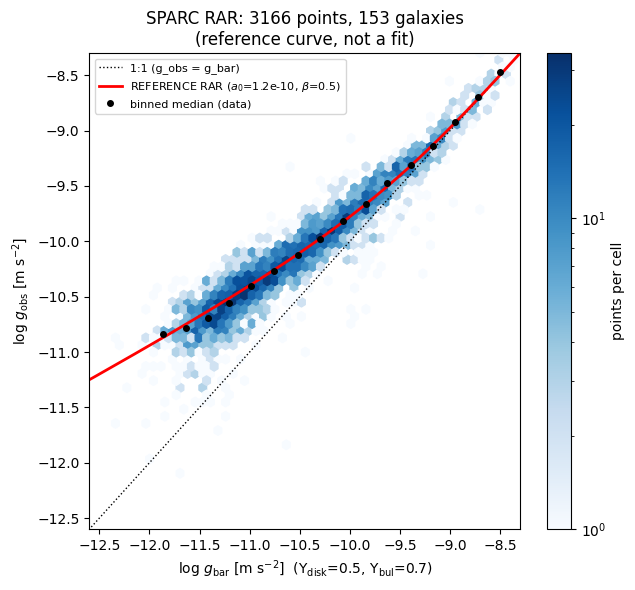

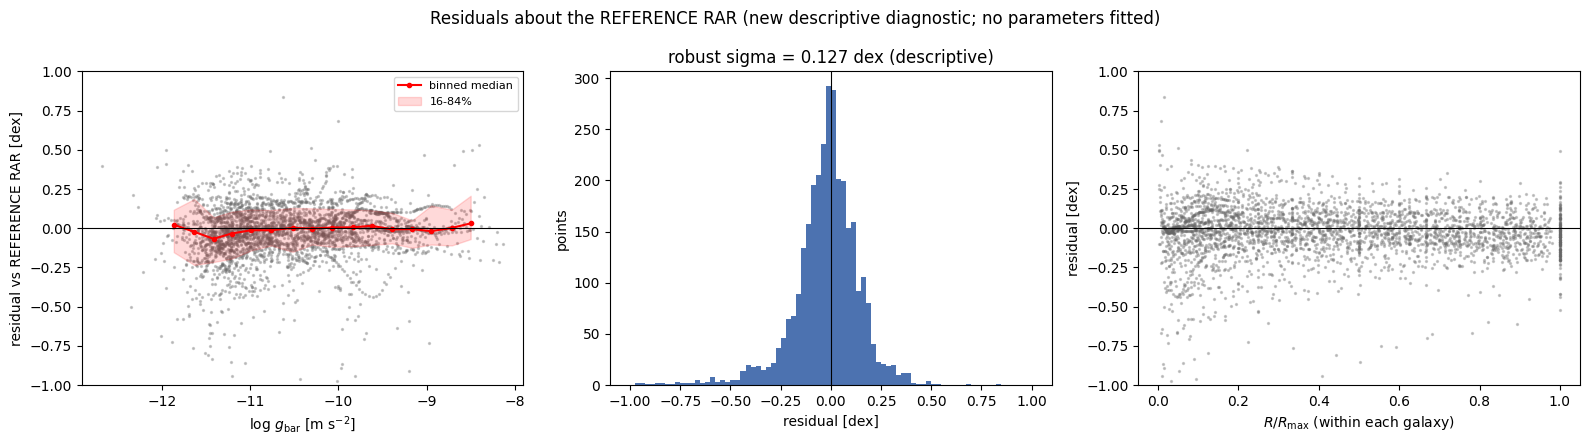

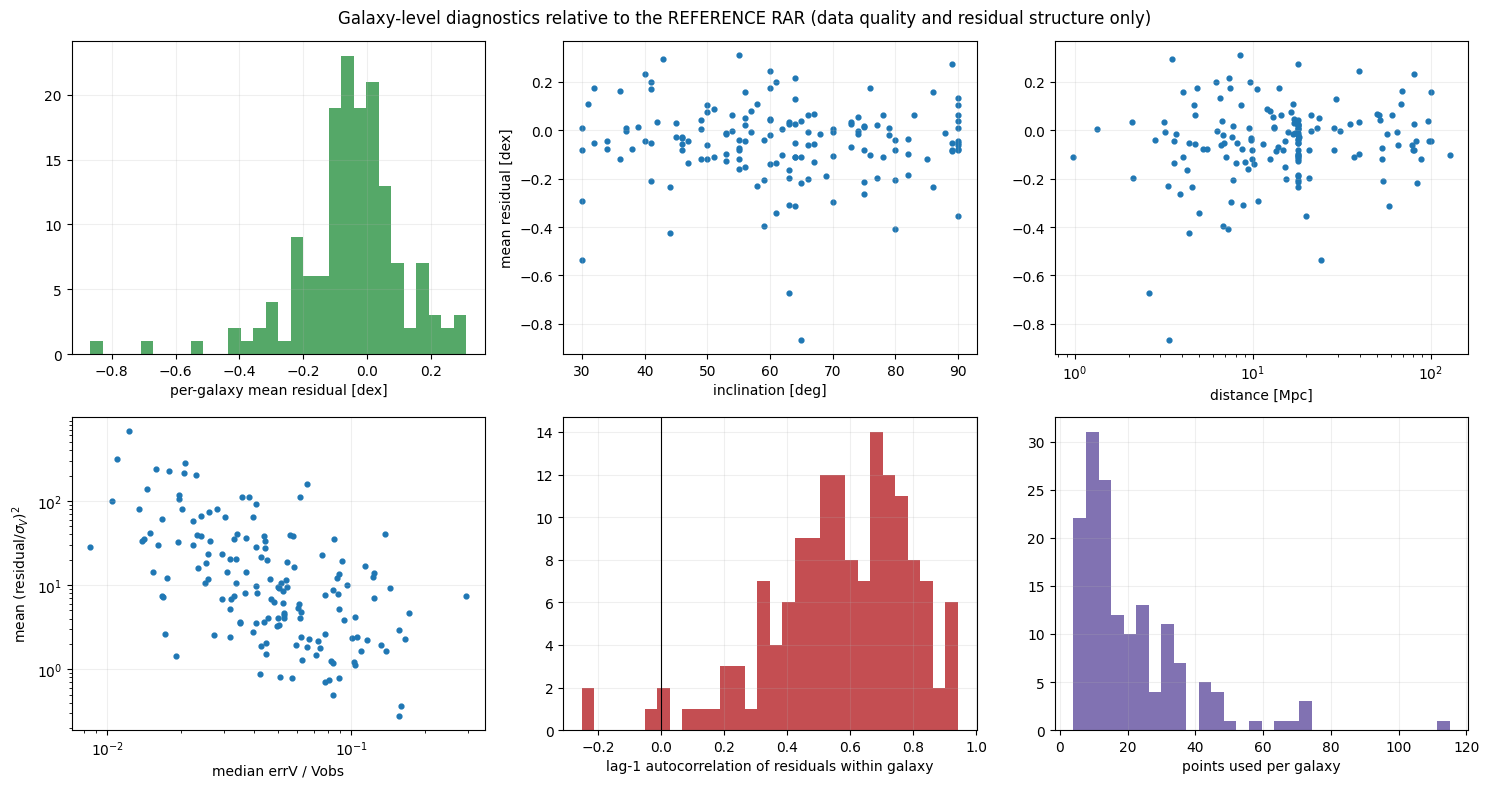

In [13]:
lg = np.linspace(-13.0, -8.0, 400)
ref_curve = log_rar_generalized(lg, np.log10(REF["a0_ms2"]), REF["beta"])
good_bins = binned[binned.enough_points]

# Figure 1: RAR with reference curve
fig, ax = plt.subplots(figsize=(6.5, 6))
hb = ax.hexbin(use.log_g_bar_ref, use.log_g_obs, gridsize=60, bins="log", cmap="Blues", mincnt=1)
ax.plot(lg, lg, "k:", lw=1, label="1:1 (g_obs = g_bar)")
ax.plot(lg, ref_curve, "r-", lw=2, label=r"REFERENCE RAR ($a_0$=1.2e-10, $\beta$=0.5)")
ax.plot(good_bins.log_gbar_center, good_bins.median_log_gobs, "ko", ms=4, label="binned median (data)")
ax.set_xlim(-12.6, -8.3); ax.set_ylim(-12.6, -8.3)
ax.set_xlabel(r"log $g_\mathrm{bar}$ [m s$^{-2}$]  ($\Upsilon_\mathrm{disk}$=0.5, $\Upsilon_\mathrm{bul}$=0.7)")
ax.set_ylabel(r"log $g_\mathrm{obs}$ [m s$^{-2}$]")
ax.set_title(f"SPARC RAR: {N_USE} points, {G_USE} galaxies\n(reference curve, not a fit)")
fig.colorbar(hb, ax=ax, label="points per cell"); ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "02_rar_observed_vs_baryonic.png", dpi=170); plt.show()

# Figure 2: residuals
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(use.log_g_bar_ref, use.resid_ref_dex, s=2, alpha=0.3, color="0.4")
ax[0].plot(good_bins.log_gbar_center, good_bins.median_resid, "r-o", ms=3, label="binned median")
ax[0].fill_between(good_bins.log_gbar_center, good_bins.p16_resid, good_bins.p84_resid, color="r", alpha=0.15, label="16-84%")
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_ylim(-1, 1)
ax[0].set_xlabel(r"log $g_\mathrm{bar}$ [m s$^{-2}$]"); ax[0].set_ylabel("residual vs REFERENCE RAR [dex]"); ax[0].legend(fontsize=8)
ax[1].hist(use.resid_ref_dex, bins=80, range=(-1, 1), color="#4C72B0")
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlabel("residual [dex]"); ax[1].set_ylabel("points")
ax[1].set_title(f"robust sigma = {summary_stats['robust_sigma_residual_dex']:.3f} dex (descriptive)")
ax[2].scatter(use.R_over_Rmax, use.resid_ref_dex, s=2, alpha=0.3, color="0.4")
ax[2].axhline(0, color="k", lw=0.8); ax[2].set_ylim(-1, 1)
ax[2].set_xlabel(r"$R / R_\mathrm{max}$ (within each galaxy)"); ax[2].set_ylabel("residual [dex]")
fig.suptitle("Residuals about the REFERENCE RAR (new descriptive diagnostic; no parameters fitted)")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "02_rar_residuals.png", dpi=170); plt.show()

# Figure 3: galaxy-level data-quality diagnostics
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].hist(gal.mean_resid_ref_dex.dropna(), bins=30, color="#55A868"); ax[0, 0].set_xlabel("per-galaxy mean residual [dex]")
ax[0, 1].scatter(gal.inc_deg, gal.mean_resid_ref_dex, s=12); ax[0, 1].set_xlabel("inclination [deg]"); ax[0, 1].set_ylabel("mean residual [dex]")
ax[0, 2].scatter(gal.distance_mpc, gal.mean_resid_ref_dex, s=12); ax[0, 2].set_xscale("log"); ax[0, 2].set_xlabel("distance [Mpc]")
ax[1, 0].scatter(gal.median_frac_errV, gal.chi2_per_point_sigmaV, s=12); ax[1, 0].set_xscale("log"); ax[1, 0].set_yscale("log")
ax[1, 0].set_xlabel("median errV / Vobs"); ax[1, 0].set_ylabel(r"mean (residual/$\sigma_V$)$^2$")
ax[1, 1].hist(gal.lag1_autocorr_resid.dropna(), bins=30, color="#C44E52"); ax[1, 1].axvline(0, color="k", lw=0.8)
ax[1, 1].set_xlabel("lag-1 autocorrelation of residuals within galaxy")
ax[1, 2].hist(gal.n_points_used, bins=30, color="#8172B2"); ax[1, 2].set_xlabel("points used per galaxy")
for a in ax.flat:
    a.grid(alpha=0.2)
fig.suptitle("Galaxy-level diagnostics relative to the REFERENCE RAR (data quality and residual structure only)")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "02_galaxy_level_diagnostics.png", dpi=170); plt.show()

Saved 153 galaxies to /content/drive/MyDrive/RAR_Universality_Research/05_Results/Figures/02_galaxy_rotation_curves_and_residuals.pdf


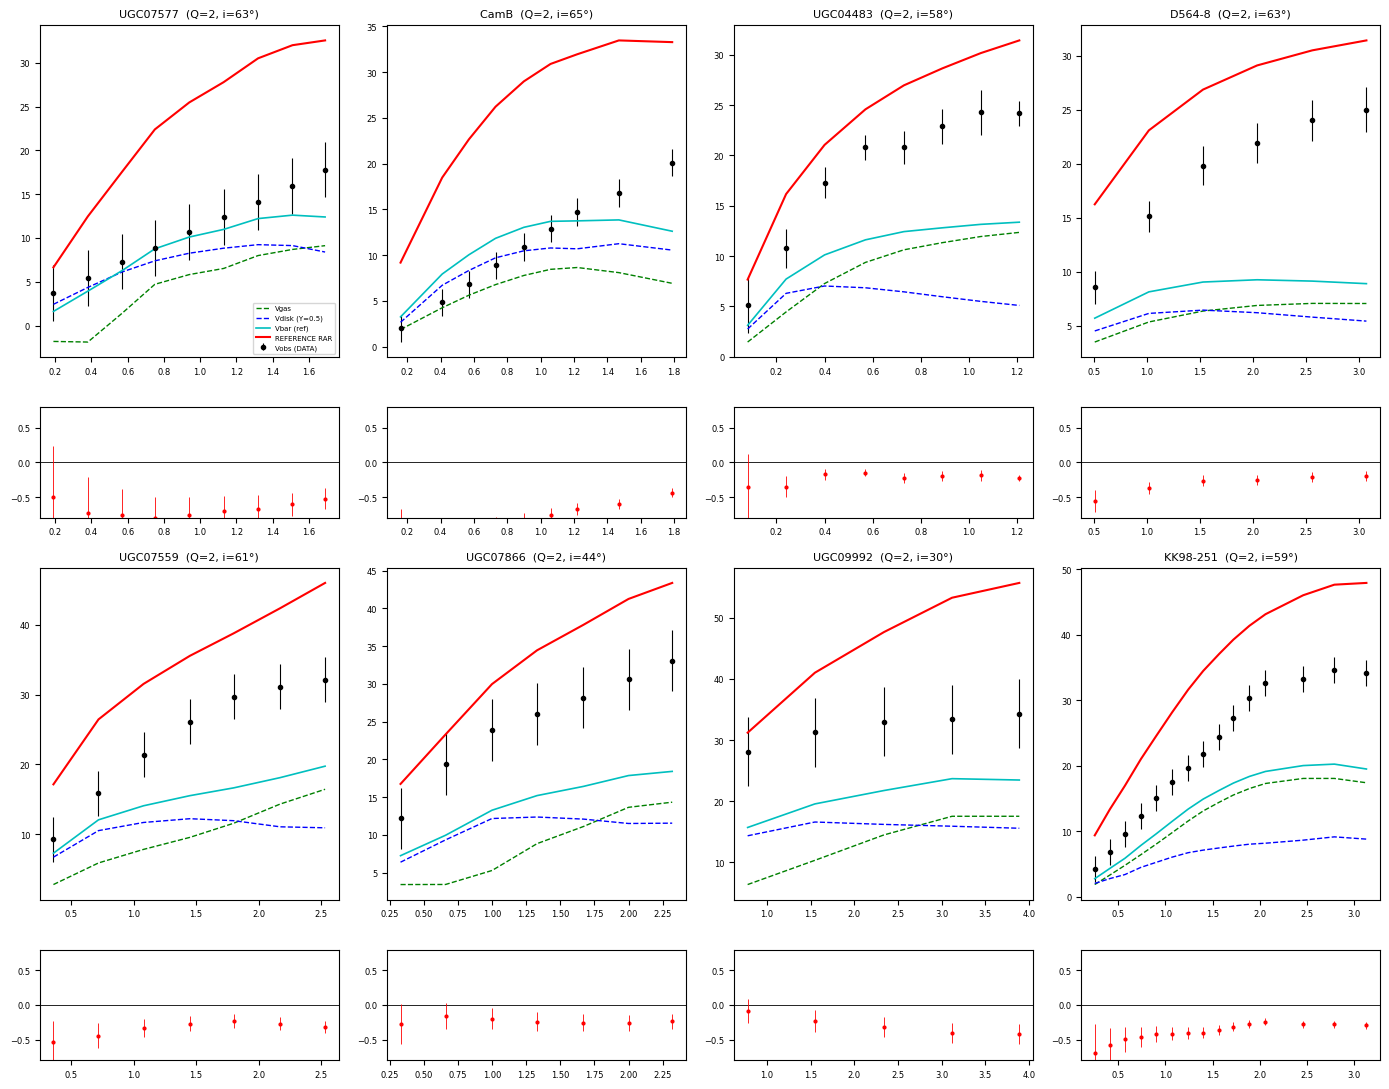

In [14]:
# Figure 4: per-galaxy rotation curves and residual profiles (all eligible galaxies, multi-page PDF)
def plot_galaxy(axv, axr, g):
    d = df[df.galaxy == g].sort_values("Rad")
    u = d[d.included_in_log_analysis]
    axv.errorbar(d.Rad, d.Vobs, yerr=d.errV, fmt="o", ms=3, color="k", lw=0.8, label="Vobs (DATA)")
    axv.plot(d.Rad, d.Vgas, "g--", lw=1, label="Vgas")
    axv.plot(d.Rad, np.sqrt(REF["upsilon_disk"]) * d.Vdisk, "b--", lw=1, label="Vdisk (Y=0.5)")
    if (d.Vbul > 0).any():
        axv.plot(d.Rad, np.sqrt(REF["upsilon_bulge"]) * d.Vbul, "m--", lw=1, label="Vbul (Y=0.7)")
    axv.plot(d.Rad, d.Vbar_ref_kms, "c-", lw=1.2, label="Vbar (ref)")
    if len(u):
        v_ref = np.sqrt(10 ** u.log_g_rar_ref * u.Rad * KPC_IN_M) / KMS_IN_MS
        axv.plot(u.Rad, v_ref, "r-", lw=1.5, label="REFERENCE RAR")
    q = gal.loc[gal.galaxy == g, "quality_flag_Q"].iloc[0]
    axv.set_title(f"{g}  (Q={int(q)}, i={d.inc_deg.iloc[0]:.0f}°)", fontsize=8); axv.tick_params(labelsize=6)
    axr.axhline(0, color="k", lw=0.6)
    if len(u):
        axr.errorbar(u.Rad, u.resid_ref_dex, yerr=u.sigma_log_gobs_V, fmt="o", ms=2, lw=0.6, color="r")
    axr.set_ylim(-0.8, 0.8); axr.tick_params(labelsize=6)

galaxies_sorted = list(gal.sort_values("Vobs_max_kms").galaxy)
PER_PAGE = 8
pdf_path = FIGURES_DIR / "02_galaxy_rotation_curves_and_residuals.pdf"
with PdfPages(pdf_path) as pdf:
    for start in range(0, len(galaxies_sorted), PER_PAGE):
        fig, axes = plt.subplots(4, 4, figsize=(14, 11), gridspec_kw={"height_ratios": [3, 1, 3, 1]})
        for k, g in enumerate(galaxies_sorted[start:start + PER_PAGE]):
            r, c = (k // 4) * 2, k % 4
            plot_galaxy(axes[r, c], axes[r + 1, c], g)
        for k in range(len(galaxies_sorted[start:start + PER_PAGE]), PER_PAGE):
            r, c = (k // 4) * 2, k % 4
            axes[r, c].axis("off"); axes[r + 1, c].axis("off")
        axes[0, 0].legend(fontsize=5, loc="lower right")
        fig.suptitle("SPARC rotation curves (DATA), baryonic components at reference Y*, REFERENCE RAR prediction; "
                     "lower panels: residual [dex] with sigma_V", fontsize=9)
        fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
print(f"Saved {len(galaxies_sorted)} galaxies to {pdf_path}")

# Quick-look PNG of the first page
fig, axes = plt.subplots(4, 4, figsize=(14, 11), gridspec_kw={"height_ratios": [3, 1, 3, 1]})
for k in range(PER_PAGE):
    r, c = (k // 4) * 2, k % 4
    if k < len(galaxies_sorted):
        plot_galaxy(axes[r, c], axes[r + 1, c], galaxies_sorted[k])
    else:
        axes[r, c].axis("off"); axes[r + 1, c].axis("off")
axes[0, 0].legend(fontsize=5, loc="lower right")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "02_galaxy_rotation_curves_examples.png", dpi=140); plt.show()

## 11. Unit, Consistency and Physical-Plausibility Checks

In [15]:
# Units: a hand-checkable value. V = 100 km/s at R = 1 kpc -> (1e5 m/s)^2 / 3.0857e19 m = 3.2408e-10 m/s^2
g_test = (100 * KMS_IN_MS) ** 2 / (1 * KPC_IN_M)
record_check("Units", "100 km/s at 1 kpc gives 3.2408e-10 m/s^2", abs(g_test / 3.2408e-10 - 1) < 1e-4, f"{g_test:.5e}")

# Consistency: recomputed accelerations agree with the Phase 1 values (same formula)
if "g_obs_ms2_derived" in pts_p1.columns:
    c = df.merge(pts_p1[["galaxy", "point_index", "g_obs_ms2_derived", "g_bar_ms2_derived_fid"]], on=["galaxy", "point_index"])
    d1 = float(np.nanmax(np.abs(c.g_obs / c.g_obs_ms2_derived - 1)))
    d2 = float(np.nanmax(np.abs((c.g_bar_ref - c.g_bar_ms2_derived_fid) / c.g_obs)))
    record_check("Consistency", "g_obs and g_bar agree with Phase 1 unit-check values", d1 < 1e-12 and d2 < 1e-12,
                 f"max rel diff g_obs {d1:.1e}; g_bar {d2:.1e}")
record_check("Consistency", "g_bar components sum to g_bar_ref",
             np.allclose(df.g_gas + 0.5 * df.g_disk_ups1 + 0.7 * df.g_bul_ups1, df.g_bar_ref, rtol=1e-12, atol=0), "ok")
record_check("Consistency", "Vbar_ref^2 / R reproduces g_bar_ref",
             np.allclose(np.sign(df.Vbar_ref_kms) * df.Vbar_ref_kms ** 2 * KMS_IN_MS ** 2 / (df.Rad * KPC_IN_M), df.g_bar_ref, rtol=1e-10), "ok")
record_check("Consistency", "galaxy table point counts sum to point table", int(gal.n_points_total.sum()) == len(df), f"{len(df)}")
record_check("Consistency", "galaxy_index is a contiguous 0..N-1 integer index",
             sorted(df.galaxy_index.unique()) == list(range(df.galaxy.nunique())), "ok")
hdr_ok = all(abs(hdr_dist[g] - gal_p1.set_index("galaxy").loc[g, "distance_mpc"]) <= 0.011 for g in hdr_dist if np.isfinite(hdr_dist[g]))
record_check("Consistency", "rotmod header distances equal MRT distances", hdr_ok, "ok" if hdr_ok else "mismatch", severity="warning")

# Distance scaling used by later nuisance sampling: R ∝ D and V_k ∝ sqrt(D) leave g_bar unchanged, while g_obs ∝ 1/D
s = 1.37
gbar_scaled = (df.Vgas * np.sqrt(s)) * np.abs(df.Vgas * np.sqrt(s)) + 0.5 * (df.Vdisk * np.sqrt(s)) ** 2 + 0.7 * (df.Vbul * np.sqrt(s)) ** 2
gbar_scaled = gbar_scaled * KMS_IN_MS ** 2 / (df.Rad * s * KPC_IN_M)
gobs_scaled = (df.Vobs * KMS_IN_MS) ** 2 / (df.Rad * s * KPC_IN_M)
record_check("Consistency", "distance rescaling: g_bar invariant, g_obs ∝ 1/D",
             np.allclose(gbar_scaled, df.g_bar_ref, rtol=1e-12) and np.allclose(gobs_scaled * s, df.g_obs, rtol=1e-12), f"tested with D x {s}")

# Physical plausibility
lo, hi = 1e-13, 1e-8
frac_out = float((~use.g_obs.between(lo, hi)).mean())
record_check("Plausibility", "g_obs within 1e-13 to 1e-8 m/s^2 for >= 99% of points", frac_out <= 0.01, f"{frac_out:.4f} outside")
record_check("Plausibility", "median log g_obs between -11.5 and -9.5", -11.5 < use.log_g_obs.median() < -9.5, f"{use.log_g_obs.median():.2f}")
frac_below = float((use.g_obs < use.g_bar_ref).mean())
record_check("Plausibility", "g_obs < g_bar_ref (super-baryonic) in fewer than 20% of points", frac_below < 0.2,
             f"{frac_below:.3f} of points (expected for some inner points given errors and reference Y*)", severity="warning")
record_check("Plausibility", "residual median within ±0.2 dex of the reference curve", abs(summary_stats["median_residual_dex"]) < 0.2,
             f"{summary_stats['median_residual_dex']:.3f} dex", severity="warning")
record_check("Plausibility", "sigma_log_gobs_V finite and positive for used points",
             bool(np.isfinite(use.sigma_log_gobs_V).all() and (use.sigma_log_gobs_V > 0).all()), "ok")
record_check("Plausibility", "inclination error term finite for all galaxies", bool(np.isfinite(df.sigma_log_gobs_inc_galaxy).all()),
             f"max {df.sigma_log_gobs_inc_galaxy.max():.3f} dex", severity="warning")

# Original data unchanged
after = [r.relative_path for r in sparc_manifest.itertuples() if sha256_of(PROJECT_ROOT / r.relative_path) != r.sha256]
record_check("Integrity", "original SPARC files unchanged after the run", not after, after[:5] or f"{len(sparc_manifest)} files")
RAW_CHECKSUM_AFTER = hashlib.sha256(pd.util.hash_pandas_object(df.sort_values(["galaxy", "point_index"])[["galaxy"] + DATA_COLS],
                                                                index=False).values.tobytes()).hexdigest()
record_check("Integrity", "observational columns unchanged in memory", RAW_CHECKSUM_AFTER == RAW_CHECKSUM, "hash compared")

checks = pd.DataFrame(CHECKS)
print(checks.status.value_counts().to_string())
display(checks)

INFO: [PASS] Units | 100 km/s at 1 kpc gives 3.2408e-10 m/s^2 | 3.24078e-10


INFO:rar_phase2:[PASS] Units | 100 km/s at 1 kpc gives 3.2408e-10 m/s^2 | 3.24078e-10


INFO: [PASS] Consistency | g_obs and g_bar agree with Phase 1 unit-check values | max rel diff g_obs 4.4e-16; g_bar 2.0e-15


INFO:rar_phase2:[PASS] Consistency | g_obs and g_bar agree with Phase 1 unit-check values | max rel diff g_obs 4.4e-16; g_bar 2.0e-15


INFO: [PASS] Consistency | g_bar components sum to g_bar_ref | ok


...

INFO:rar_phase2:[PASS] Integrity | original SPARC files unchanged after the run | 176 files


INFO: [PASS] Integrity | observational columns unchanged in memory | hash compared


INFO:rar_phase2:[PASS] Integrity | observational columns unchanged in memory | hash compared


status
PASS    36


,section,check,status,severity,detail
0,Inputs,SPARC files unchanged since Phase 1 (SHA-256),PASS,critical,176 files verified
1,Inputs,no new rotmod files since Phase 1,PASS,warning,none
2,Phase 1,Phase 1 has no critical failures,PASS,critical,0 FAIL rows
3,Phase 1 warning,MRT parse agrees with independent corpus value...,PASS,critical,175 galaxies compared; max |diff| {'distance_m...
4,Phase 1 warning,"parsed Q in {1,2,3} and inclinations in [0, 90...",PASS,critical,"Q values [1, 2, 3]"
5,Sample,re-applied cuts reproduce the Phase 1 eligible...,PASS,critical,only Phase 1: []; only recomputed: []
6,Sample,eligible galaxies = 153,PASS,critical,153 galaxies
7,Sample,eligible radial points = 3168,PASS,critical,3168 points
8,Sample,raw rotmod values identical to the Phase 1 poi...,PASS,critical,unmatched rows 0; max |diff| 0.0
9,Exclusions,no galaxy loses all its points,PASS,warning,none


## 12. Save Processed Tables and Model Inputs

* `sparc_rar_points_baseline.csv`: every eligible point (3,168 rows) with DATA columns unchanged, DERIVED accelerations and uncertainty components, flags, and REFERENCE residuals.
* `sparc_rar_galaxies_baseline.csv`: one row per eligible galaxy with the nuisance inputs (D, e_D, i, e_i) and descriptive diagnostics.
* `sparc_rar_model_inputs.npz` + metadata JSON: arrays in the form later hierarchical and correlated-error models need. Υ★ = 1 components are stored, so no reference Υ★ is baked in.
* Plus the reference-parameter table, binned residuals, point exclusions, Phase 1 warning assessment, check register, data dictionary and an output manifest with checksums.

In [16]:
point_cols = (["galaxy", "galaxy_index", "point_index"] + DATA_COLS +
              ["distance_mpc", "e_distance_mpc", "inc_deg", "e_inc_deg", "quality_flag_Q", "R_over_Rmax",
               "g_obs", "g_gas", "g_disk_ups1", "g_bul_ups1", "g_bar_ref", "Vbar_ref_kms",
               "log_g_obs", "log_g_bar_ref", "sigma_log_gobs_V", "sigma_log_gobs_D_galaxy", "sigma_log_gobs_inc_galaxy",
               "included_in_log_analysis", "exclusion_reason", "log_g_rar_ref", "resid_ref_dex", "resid_ref_over_sigmaV"])
out_points = df[point_cols].sort_values(["galaxy_index", "point_index"])
assert len(out_points) == len(raw), "point table row count changed"
out_points.to_csv(OUT_POINTS, index=False)
gal.sort_values("galaxy_index").to_csv(OUT_GALAXIES, index=False)
binned.drop(columns="bin").to_csv(OUT_BINNED, index=False)
ref_pars.to_csv(OUT_REFPARS, index=False)
(exclusions_table if len(exclusions_table) else
 pd.DataFrame({"status": ["NONE"], "reason": ["No point-level numerical exclusions were needed."]})).to_csv(OUT_EXCL, index=False)
warn_assessment.to_csv(OUT_WARN, index=False)

# Arrays for later modelling (all eligible points; use 'included_in_log_analysis' or recompute g_bar for sampled Upsilon)
o = out_points
gtab = gal.sort_values("galaxy_index")
np.savez_compressed(
    OUT_NPZ,
    galaxy_names=gtab.galaxy.to_numpy(dtype=str), galaxy_index=o.galaxy_index.to_numpy(np.int32),
    R_kpc=o.Rad.to_numpy(float), Vobs_kms=o.Vobs.to_numpy(float), errV_kms=o.errV.to_numpy(float),
    Vgas_kms=o.Vgas.to_numpy(float), Vdisk_ups1_kms=o.Vdisk.to_numpy(float), Vbul_ups1_kms=o.Vbul.to_numpy(float),
    included_ref=o.included_in_log_analysis.to_numpy(bool),
    gal_D_mpc=gtab.distance_mpc.to_numpy(float), gal_eD_mpc=gtab.e_distance_mpc.to_numpy(float),
    gal_inc_deg=gtab.inc_deg.to_numpy(float), gal_einc_deg=gtab.e_inc_deg.to_numpy(float),
    gal_has_bulge=gtab.has_bulge.to_numpy(bool), gal_Q=gtab.quality_flag_Q.to_numpy(int),
)
npz_meta = {
    "created_utc": RUN_TIMESTAMP, "source": "SPARC rotmod files + SPARC_Lelli2016c.mrt via Phase 1 audit",
    "n_galaxies": int(gtab.shape[0]), "n_points": int(len(o)),
    "units": {"R_kpc": "kpc", "*_kms": "km/s", "gal_D_mpc": "Mpc", "gal_inc_deg": "deg"},
    "conventions": {"Vgas": "signed; enters V_bar^2 as Vgas*|Vgas|", "Vdisk_ups1_kms/Vbul_ups1_kms": "for Upsilon = 1",
                    "distance_scaling": "R ∝ D, V_component ∝ sqrt(D), V_obs independent of D => g_bar invariant, g_obs ∝ 1/D",
                    "inclination_scaling": "V_obs ∝ 1/sin(i) relative to the catalogue inclination"},
    "kpc_in_m": KPC_IN_M, "reference_parameters_not_fitted": REF,
    "selection": f"Q <= {Q_MAX}, inc >= {INC_MIN_DEG} deg (proposal Section 3)",
}
OUT_NPZ_META.write_text(json.dumps(npz_meta, indent=2))
print("Saved processed tables and model inputs.")

Saved processed tables and model inputs.


In [17]:
DOC = {
 "galaxy": ("Galaxy identifier", "-", "DATA"), "galaxy_index": ("Contiguous 0..N-1 integer index for modelling", "-", "DERIVED"),
 "point_index": ("Row order in the rotmod file", "-", "DATA (order)"),
 "Rad": ("Galactocentric radius", "kpc", "DATA"), "Vobs": ("Observed rotation velocity", "km/s", "DATA"),
 "errV": ("Uncertainty on Vobs", "km/s", "DATA"), "Vgas": ("Gas contribution (signed)", "km/s", "DATA"),
 "Vdisk": ("Disk contribution at Upsilon = 1", "km/s", "DATA"), "Vbul": ("Bulge contribution at Upsilon = 1", "km/s", "DATA"),
 "SBdisk": ("Disk surface brightness", "Lsun/pc^2", "DATA"), "SBbul": ("Bulge surface brightness", "Lsun/pc^2", "DATA"),
 "distance_mpc": ("Distance (SPARC MRT)", "Mpc", "DATA"), "e_distance_mpc": ("Distance error (SPARC MRT)", "Mpc", "DATA"),
 "inc_deg": ("Inclination (SPARC MRT)", "deg", "DATA"), "e_inc_deg": ("Inclination error (SPARC MRT)", "deg", "DATA"),
 "quality_flag_Q": ("SPARC quality flag", "-", "DATA"),
 "R_over_Rmax": ("Radius divided by the galaxy's largest radius", "-", "DERIVED"),
 "g_obs": ("Vobs^2 / R", "m s^-2", "DERIVED"), "g_gas": ("Vgas|Vgas| / R", "m s^-2", "DERIVED"),
 "g_disk_ups1": ("Vdisk^2 / R at Upsilon = 1", "m s^-2", "DERIVED"), "g_bul_ups1": ("Vbul^2 / R at Upsilon = 1", "m s^-2", "DERIVED"),
 "g_bar_ref": ("g_gas + 0.5 g_disk + 0.7 g_bul", "m s^-2", "REFERENCE (M/L)"),
 "Vbar_ref_kms": ("Signed sqrt of g_bar_ref * R", "km/s", "REFERENCE (M/L)"),
 "log_g_obs": ("log10 g_obs", "dex (m s^-2)", "DERIVED"), "log_g_bar_ref": ("log10 g_bar_ref (NaN if g_bar_ref <= 0)", "dex (m s^-2)", "REFERENCE (M/L)"),
 "sigma_log_gobs_V": ("2 errV / (Vobs ln10): independent per point", "dex", "DERIVED"),
 "sigma_log_gobs_D_galaxy": ("e_D / (D ln10): fully correlated within a galaxy", "dex", "DERIVED"),
 "sigma_log_gobs_inc_galaxy": ("2 e_i / (tan i ln10): fully correlated within a galaxy", "dex", "DERIVED"),
 "included_in_log_analysis": ("False if a log or uncertainty cannot be computed (see exclusion_reason)", "-", "FLAG"),
 "exclusion_reason": ("Why a point is excluded from log-space analysis", "-", "FLAG"),
 "log_g_rar_ref": ("Generalised RAR at a0 = 1.2e-10, beta = 0.5", "dex (m s^-2)", "REFERENCE"),
 "resid_ref_dex": ("log_g_obs - log_g_rar_ref", "dex", "NEW DIAGNOSTIC"),
 "resid_ref_over_sigmaV": ("resid_ref_dex / sigma_log_gobs_V", "-", "NEW DIAGNOSTIC"),
 "mean_resid_ref_dex": ("Per-galaxy mean residual vs reference", "dex", "NEW DIAGNOSTIC"),
 "median_resid_ref_dex": ("Per-galaxy median residual", "dex", "NEW DIAGNOSTIC"),
 "std_resid_ref_dex": ("Per-galaxy residual standard deviation", "dex", "NEW DIAGNOSTIC"),
 "chi2_per_point_sigmaV": ("Mean (residual/sigma_V)^2; sigma_V only, so not a goodness-of-fit", "-", "NEW DIAGNOSTIC"),
 "lag1_autocorr_resid": ("Lag-1 autocorrelation of residuals ordered by radius", "-", "NEW DIAGNOSTIC"),
}
def describe(col):
    if col in DOC: return DOC[col]
    if col.startswith("n_"): return ("Count", "-", "DERIVED")
    return ("See notebook section that creates the table", "-", "DERIVED / DIAGNOSTIC")
dd = []
for path in (OUT_POINTS, OUT_GALAXIES, OUT_BINNED, OUT_REFPARS, OUT_EXCL, OUT_WARN):
    for c in pd.read_csv(path, nrows=0).columns:
        d, u, o_ = describe(c)
        dd.append({"table": path.name, "column": c, "description": d, "unit": u, "label": o_})
pd.DataFrame(dd).to_csv(OUT_DICT, index=False)
pd.DataFrame(CHECKS).to_csv(OUT_CHECKS, index=False)

## 13. Report and Completion Summary

Writes `05_Results/Tables/RAR_Baseline_Report.md` and an output manifest with checksums. If any **critical** check failed, the final cell raises an error after saving, so it cannot be missed.

In [18]:
checks = pd.DataFrame(CHECKS)
n_fail, n_warn = int((checks.status == "FAIL").sum()), int((checks.status == "WARN").sum())
def md_table(d):
    if d is None or len(d) == 0: return "_none_\n"
    d = d.astype(str).replace({"nan": ""})
    return "| " + " | ".join(d.columns) + " |\n|" + "---|" * len(d.columns) + "\n" + "".join("| " + " | ".join(r) + " |\n" for r in d.values)

report = f'''# RAR Baseline Report — Phase 2 (SPARC only)

*Generated by `02_RAR_Baseline.ipynb` on {RUN_TIMESTAMP} (UTC). This file exists only if the notebook ran.*

## Scope
SPARC only (the Phase 1 cross-survey gate did not pass). No Bayesian inference, GP modelling, population comparison or injection–recovery was performed. No baryonic data were invented for any survey.

## Sample (DATA)
* Eligible galaxies: {df.galaxy.nunique()} (expected {EXPECTED_N_GALAXIES}); radial points: {len(df)} (expected {EXPECTED_N_POINTS}).
* Original SPARC files verified unchanged against Phase 1 checksums.
* Point-level numerical exclusions from log-space analysis: {len(df) - N_USE} points (kept in all tables with reasons); points used: {N_USE} in {G_USE} galaxies.

{md_table(excl_summary.reset_index().rename(columns={"index": "criterion"}))}
## Phase 1 warnings
{md_table(warn_assessment[["section", "check", "affects_notebook_02", "assessment"]])}
## REFERENCE parameters (not fitted)
{md_table(ref_pars[["parameter", "value", "unit", "role"]])}
## NEW DIAGNOSTIC: residuals about the reference RAR (descriptive only)
* Median residual: {summary_stats["median_residual_dex"]:.3f} dex; mean: {summary_stats["mean_residual_dex"]:.3f} dex.
* RMS: {summary_stats["rms_residual_dex"]:.3f} dex; robust sigma (1.4826 MAD): {summary_stats["robust_sigma_residual_dex"]:.3f} dex.
* Median per-point measurement term sigma_V: {summary_stats["median_sigma_log_gobs_V_dex"]:.3f} dex.
* Median within-galaxy lag-1 residual autocorrelation: {gal.lag1_autocorr_resid.median():.2f}.
* These numbers describe this data set relative to fixed published parameters. They are **not** estimates of a0, beta or intrinsic scatter; those come from the hierarchical model in later phases. The literature observed scatter (~{LITERATURE_CONTEXT["observed_scatter_dex"]} dex, McGaugh et al. 2016) used extra point-level cuts not applied here.

## Checks
{len(checks)} checks: {n_fail} FAIL, {n_warn} WARN.
{md_table(checks[checks.status != "PASS"][["section", "check", "status", "detail"]])}
## Outputs
* Tables: `03_Processed_Data/` ({OUT_POINTS.name}, {OUT_GALAXIES.name}, {OUT_BINNED.name}, {OUT_REFPARS.name}, {OUT_EXCL.name}, {OUT_WARN.name}, {OUT_CHECKS.name}, {OUT_DICT.name}, {OUT_NPZ.name}, {OUT_NPZ_META.name}, {OUT_MANIFEST.name})
* Figures: `05_Results/Figures/02_*`

## Preserved for later phases
Per-point Υ★ = 1 component accelerations, signed gas term, σ_V (independent) and galaxy-level σ_D and σ_i (correlated, stored separately), D, e_D, i, e_i, contiguous galaxy indices, and radial ordering for correlated-error modelling.
'''
REPORT_PATH.write_text(report, encoding="utf-8")

outs = [OUT_POINTS, OUT_GALAXIES, OUT_BINNED, OUT_REFPARS, OUT_EXCL, OUT_WARN, OUT_CHECKS, OUT_DICT, OUT_NPZ, OUT_NPZ_META,
        REPORT_PATH, LOG_PATH] + sorted(FIGURES_DIR.glob("02_*"))
pd.DataFrame([{"file": str(p.relative_to(PROJECT_ROOT)), "size_bytes": p.stat().st_size,
               "sha256": sha256_of(p) if p != LOG_PATH else "(log, still open)"} for p in outs]).to_csv(OUT_MANIFEST, index=False)
print(report[:3000])

# RAR Baseline Report — Phase 2 (SPARC only)

*Generated by `02_RAR_Baseline.ipynb` on 2026-10-22T08:50:33Z (UTC). This file exists only if the notebook ran.*

## Scope
SPARC only (the Phase 1 cross-survey gate did not pass). No Bayesian inference, GP modelling, population comparison or injection–recovery was performed. No baryonic data were invented for any survey.

## Sample (DATA)
* Eligible galaxies: 153 (expected 153); radial points: 3168 (expected 3168).
* Original SPARC files verified unchanged against Phase 1 checksums.
* Point-level numerical exclusions from log-space analysis: 2 points (kept in all tables with reasons); points used: 3166 in 153 galaxies.

| criterion | n_points | n_galaxies |
|---|---|---|
| R_nonpositive | 0 | 0 |
| Vobs_nonpositive | 0 | 0 |
| errV_nonpositive | 0 | 0 |
| nonfinite_input | 0 | 0 |
| g_bar_ref_nonpositive_(depends_on_Upsilon) | 2 | 1 |

## Phase 1 warnings
| section | check | affects_notebook_02 | assessment |
|---|---|---|---|
| SPARC MRT |

In [19]:
print("=" * 70); print("PHASE 2 — RAR BASELINE SUMMARY"); print("=" * 70)
print(f"Sample: {df.galaxy.nunique()} galaxies, {len(df)} points (expected {EXPECTED_N_GALAXIES} / {EXPECTED_N_POINTS})")
print(f"Used in log-space analysis: {N_USE} points in {G_USE} galaxies; numerical exclusions: {len(df) - N_USE}")
print(f"REFERENCE RAR: a0 = {REF['a0_ms2']:.2e} m/s^2, beta = {REF['beta']}, Y_disk = {REF['upsilon_disk']}, Y_bul = {REF['upsilon_bulge']} (not fitted)")
print(f"NEW DIAGNOSTIC: median residual {summary_stats['median_residual_dex']:+.3f} dex, robust sigma {summary_stats['robust_sigma_residual_dex']:.3f} dex")
print(f"Checks: {len(checks)} | FAIL {n_fail} | WARN {n_warn}")
print(f"Report: {REPORT_PATH}")
if n_fail:
    raise RuntimeError(f"{n_fail} critical check(s) failed:\n" + checks[checks.status == "FAIL"][["check", "detail"]].to_string(index=False))
print("\nAll critical checks passed. Phase 2 complete.")

PHASE 2 — RAR BASELINE SUMMARY
Sample: 153 galaxies, 3168 points (expected 153 / 3168)
Used in log-space analysis: 3166 points in 153 galaxies; numerical exclusions: 2
REFERENCE RAR: a0 = 1.20e-10 m/s^2, beta = 0.5, Y_disk = 0.5, Y_bul = 0.7 (not fitted)
NEW DIAGNOSTIC: median residual -0.013 dex, robust sigma 0.127 dex
Checks: 36 | FAIL 0 | WARN 0
Report: /content/drive/MyDrive/RAR_Universality_Research/05_Results/Tables/RAR_Baseline_Report.md

All critical checks passed. Phase 2 complete.
